In [39]:
%pylab inline

import numpy as np
import numpy.ma as ma

import scipy.signal as sg
import scipy.ndimage as ndimage
from scipy import interpolate

import gdal

import importlib

import matplotlib
import matplotlib.pyplot as plt
from mpl_toolkits.basemap import Basemap

import sys, os
sys.path.append('/home/tarasenko/codes/python/wind/')

import s1_with_posada as s1_pos
importlib.reload(s1_pos)

import wind_func as wnd
importlib.reload(wnd)





def readFile(filename, nbofbands=1):
    filehandle = gdal.Open(filename)
    if filehandle is None:
      print ('Unable to open ', filename)
      sys.exit(1)
    
    geotransform = filehandle.GetGeoTransform()
    geoproj = filehandle.GetProjection()
    print (geotransform)

    xsize = filehandle.RasterXSize
    ysize = filehandle.RasterYSize
    
    band_data=np.zeros((ysize, xsize, filehandle.RasterCount), dtype=np.float64)
    
    print ("[ RASTER BAND COUNT ]: ", filehandle.RasterCount)
    for band in range(filehandle.RasterCount):
      band +=1
      print ("[ GETTING BAND ]: ", band)
      scrband = filehandle.GetRasterBand(band)

      if scrband is None:
        continue
      band_data[:, :, band-1] = scrband.ReadAsArray()

    return xsize,ysize, geotransform,geoproj, band_data


def get_latlon(band_data, geotransform, nth_point=10):
    
    Xpixel, Yline = np.meshgrid(np.arange(0, band_data.shape[1], nth_point), 
                                np.arange(1, band_data.shape[0], nth_point))
    lon_rastr = geotransform[0] + Xpixel*geotransform[1] + Yline*geotransform[2]
    lat_rastr = geotransform[3] + Xpixel*geotransform[4] + Yline*geotransform[5]
    return lon_rastr, lat_rastr


def create_mask(data_A, lat_A, lon_A, data_B, lat_B, lon_B, condition = lambda x: x==2):
    #create a mask for array B from an array A of different grid
#     1) We regrid data_A to the spatial grid of data_B
#     2) Masking here is based on treshold values: we should define it with lambda function, 
#     eg: x==2 - means mask out all values, where (regridded) data_A is equal 2 
#     eg2: x>1 means that we mask out all values greater than 1, etc
    
    lon_A_1d = np.ndarray.flatten(lon_A)
    lat_A_1d = np.ndarray.flatten(lat_A)
    data_A_1d = np.ndarray.flatten(data_A)

    mask_interpolated = interpolate.griddata((lon_rastr_1d, lat_rastr_1d), data_A_1d, (lon, lat), method='nearest')
    masked_data_B = np.ma.masked_where(condition(mask_interpolated), data_B)
    
    return masked_data_B


Populating the interactive namespace from numpy and matplotlib


S1A_EW_GRDM_1SDH_20160511T023241_20160511T023346_011205_010EF1_A86C
S1A_EW_GRDM_1SDH_20160511T023241_20160511T023346_011205_010EF1_
(61.70133244365237, 0.0016526838682446305, 0.0, 80.8329976909536, 0.0, -0.0016526838682446305)
[ RASTER BAND COUNT ]:  1
[ GETTING BAND ]:  1
(3039, 14908, 1)
(304, 1491)


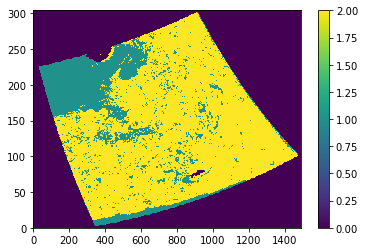

In [47]:
fpath_ice = '/home/tarasenko/data/ice_mask/'
lsdir = os.listdir(fpath_ice)

for f_ice_mask in lsdir:
    print (f_ice_mask[4:-4])
    if f_ice_mask[-4:]!='.zip':
        xsize, ysize, GT, geoproj, band_data = readFile(fpath_ice+f_ice_mask+'/icewater.tif')
        print (band_data.shape)

        band_400 = band_data.squeeze()[::10,::10]
        print (band_400.shape)

        plt.pcolormesh(band_400)
        plt.colorbar()
        plt.show()

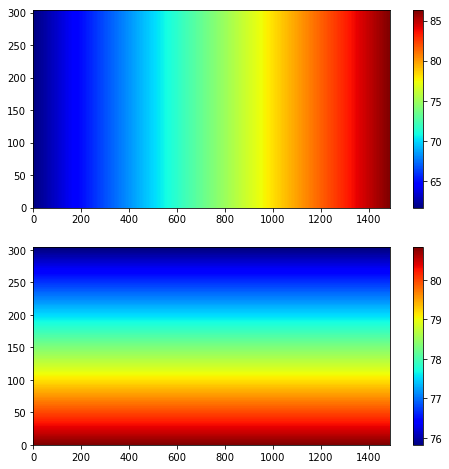

In [22]:
lon_rastr, lat_rastr = get_latlon(band_data, GT, nth_point=10)

fig1 = plt.figure(figsize = (8,8))
plt.subplot(211)
plt.pcolormesh(lon_rastr, cmap= 'jet')
# ,lat_rastr, band_400)
plt.colorbar()

plt.subplot(212)
plt.pcolormesh(lat_rastr, cmap= 'jet')
# ,lat_rastr, band_400)
plt.colorbar()
plt.show()

/usr/local/lib/python3.4/dist-packages/pyresample/kd_tree.py:389: UserWarning: Possible more than 40 neighbours within 50000.0 m for some data points
  (neighbours, radius_of_influence))


desc trajectory


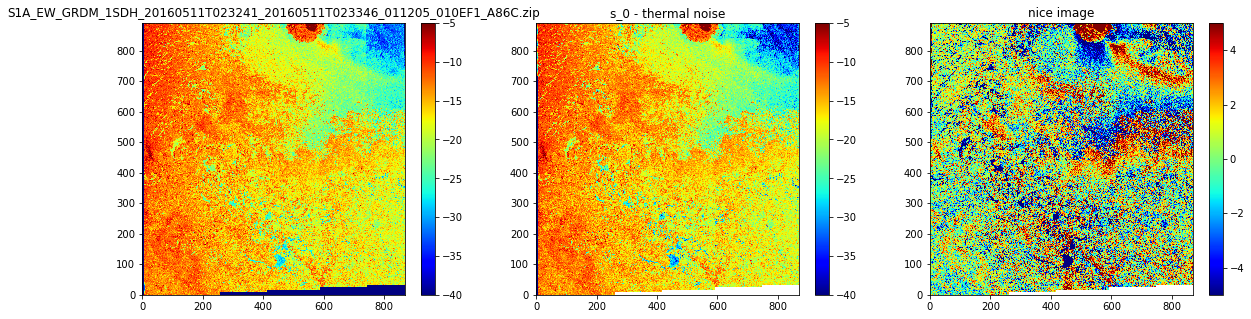

In [24]:
# 1) Import  corresponding sigma and correct thermal noise
importlib.reload(s1_pos)
importlib.reload(wnd)


# fn = wlist.fn_list[0]
fn ='S1A_EW_GRDM_1SDH_20160511T023241_20160511T023346_011205_010EF1_A86C.zip'


s0, lat, lon, inc, sigma0_corr, s0_nice, wdir_model = s1_pos.get_data(pn+fn, res_m = 500, pol = pol, wind_model = 'interim')



# 1.1. Plot 
fig_sigma = plt.figure(figsize=(20, 5))
plt.subplot(1, 3, 1)
plt.pcolormesh(10*np.log10(s0), cmap='jet')
plt.clim(-40, -5)
plt.colorbar()
plt.title(fn)

plt.subplot(1, 3, 2)
plt.pcolormesh(10*np.log10(sigma0_corr), cmap='jet')
plt.clim(-40, -5)
plt.colorbar()
plt.title('s_0 - thermal noise')


plt.subplot(1, 3, 3)
plt.pcolormesh(s0_nice, cmap='jet')
plt.clim(-5, 5)
plt.colorbar()
plt.title('nice image')

plt.show()

figname = '/home/tarasenko/Figures/tests_wind/'+fn[:-4]+'_sigma.png'
fig_sigma.savefig(figname, dpi = 300)
 

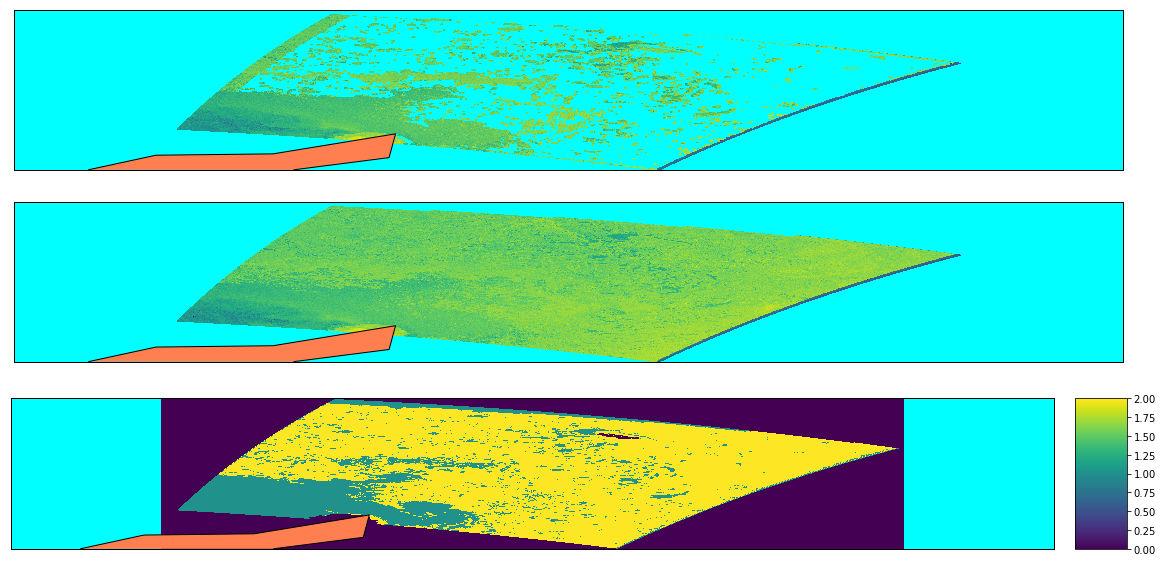

In [48]:
masked_s0_corr_test = create_mask(band_400, lat_rastr, lon_rastr, sigma0_corr, lat, lon, condition = lambda x: x==2)

  
    
    
    
plt.figure(figsize=(20,10))
plt.subplot(311)                         
m = Basemap(ellps='WGS84', lon_0 = 78, lat_0 = 75, 
            llcrnrlon=lon_rastr[0, 0]-5,
            llcrnrlat=lat_rastr[0, 0]-5, 
            urcrnrlon=lon_rastr[-1,-1]+5,
            urcrnrlat=lat_rastr[-1,-1]+5)

m.drawmapboundary(fill_color='aqua')
m.fillcontinents(color='coral',lake_color='aqua')
m.drawcoastlines()

x_s0_masked, y_s0_masked = m(lon, lat)
m.pcolormesh(x_s0_masked, y_s0_masked, 10*np.log10(masked_s0_corr_test) )



plt.subplot(312)                         
m = Basemap(ellps='WGS84', lon_0 = 78, lat_0 = 75, 
            llcrnrlon=lon_rastr[0, 0]-5,
            llcrnrlat=lat_rastr[0, 0]-5, 
            urcrnrlon=lon_rastr[-1,-1]+5,
            urcrnrlat=lat_rastr[-1,-1]+5)

m.drawmapboundary(fill_color='aqua')
m.fillcontinents(color='coral',lake_color='aqua')
m.drawcoastlines()

x_s0, y_s0 = m(lon, lat)
m.pcolormesh(x_s0, y_s0, 10*np.log10(sigma0_corr))


plt.subplot(313)                         
m = Basemap(ellps='WGS84', lon_0 = 78, lat_0 = 75, 
            llcrnrlon=lon_rastr[0, 0]-5,
            llcrnrlat=lat_rastr[0, 0]-5, 
            urcrnrlon=lon_rastr[-1,-1]+5,
            urcrnrlat=lat_rastr[-1,-1]+5)

m.drawmapboundary(fill_color='aqua')
m.fillcontinents(color='coral',lake_color='aqua')
m.drawcoastlines()

x_rastr, y_rastr = m(lon_rastr, lat_rastr)
m.pcolormesh(x_rastr, y_rastr, band_400 )
m.colorbar()

plt.show()
# print(sigma0_corr)

# plt.pcolormesh(lon, lat, 10*np.log10(sigma0_corr))
# plt.clim([-40, 0])
# plt.colorbar()
# plt.show()

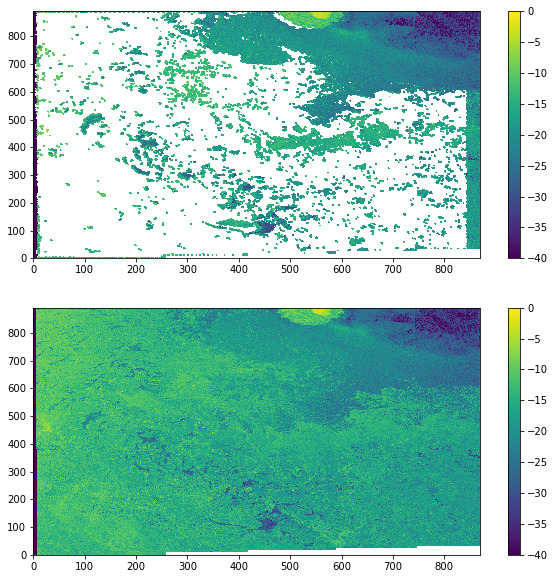

In [49]:
plt.figure(figsize=(10,10))
plt.subplot(211)
plt.pcolormesh(10*np.log10(masked_s0_corr))
plt.clim([-40, 0])
plt.colorbar()

plt.subplot(212)
plt.pcolormesh(10*np.log10(sigma0_corr))
plt.clim([-40, 0])
plt.colorbar()
plt.show()